# Kenya County Cropland Extent

Share and km² of cropland in all 47 Kenyan counties, with a bracket. A free sample from [NuaSense](https://agriculture-data.com), East African agricultural data; also on [Hugging Face](https://huggingface.co/datasets/nuasense/kenya-county-cropland-extent) (CC BY-NC 4.0).

In [1]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True, "font.size": 10})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

def load(name, hf_url):
    # On Kaggle the CSV sits under /kaggle/input; in Colab or on your machine the same table
    # is read straight from Hugging Face.
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"**/{name}", recursive=True)
    return pd.read_csv(hits[0]) if hits else pd.read_parquet(hf_url)

df = load("kenya_county_cropland_extent.csv", "https://huggingface.co/datasets/nuasense/kenya-county-cropland-extent/resolve/main/data/counties/counties.parquet")
print(f"{len(df):,} rows")
df.head()

47 rows


,country,county_id,county_name,cropland_share,cropland_km2,cropland_share_low,cropland_share_high,estimated_on
0,KE,kakamega,Kakamega,0.5751,1718.8,0.3179,0.8941,2026-09-15
1,KE,vihiga,Vihiga,0.5710,319.9,0.0309,0.8877,2026-09-15
2,KE,busia,Busia,0.5614,1019.0,0.1863,0.8729,2026-09-15
3,KE,kisii,Kisii,0.5347,698.4,0.0332,0.8313,2026-09-15
4,KE,bungoma,Bungoma,0.5329,1612.3,0.3674,0.8286,2026-09-15


## The most and least cropped counties

In [2]:
df.sort_values("cropland_share", ascending=False)[["county_name", "cropland_share", "cropland_km2", "cropland_share_low", "cropland_share_high"]].head(10)

,county_name,cropland_share,cropland_km2,cropland_share_low,cropland_share_high
0,Kakamega,0.5751,1718.8,0.3179,0.8941
1,Vihiga,0.5710,319.9,0.0309,0.8877
2,Busia,0.5614,1019.0,0.1863,0.8729
3,Kisii,0.5347,698.4,0.0332,0.8313
4,Bungoma,0.5329,1612.3,0.3674,0.8286
5,Embu,0.5028,1421.2,0.1487,0.7817
6,Migori,0.5012,1586.8,0.3055,0.7793
7,Trans Nzoia,0.4977,1237.1,0.4664,0.7738
8,Nyamira,0.4898,433.6,0.0123,0.7616
9,Uasin Gishu,0.4889,1636.0,0.5293,0.7601


## Estimate and bracket

The dot is the estimate to use; the line spans the two unadjusted satellite layers. Where the line is long, quote the bracket.

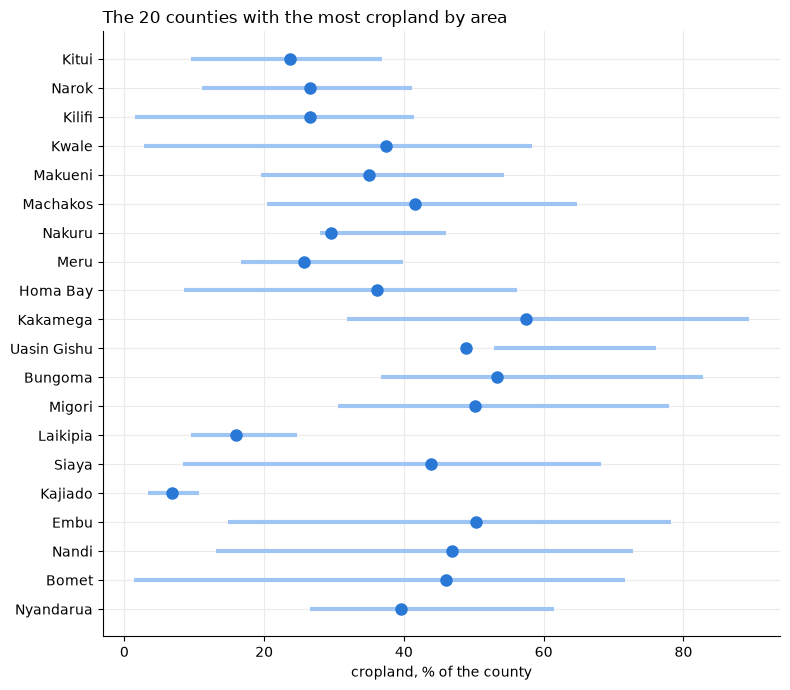

In [3]:
top = df.sort_values("cropland_km2", ascending=False).head(20).iloc[::-1]
y = range(len(top))
plt.figure(figsize=(8, 7))
plt.hlines(y, top.cropland_share_low * 100, top.cropland_share_high * 100, color="#9ec5f4", linewidth=3)
plt.plot(top.cropland_share * 100, y, "o", color=BLUE, markersize=8)
plt.yticks(y, top.county_name); plt.xlabel("cropland, % of the county")
plt.title("The 20 counties with the most cropland by area", loc="left")
plt.tight_layout(); plt.show()

In [4]:
print(f"{df.cropland_km2.sum():,.0f} km2 of cropland in Kenya; {df.cropland_km2.nlargest(10).sum() / df.cropland_km2.sum():.0%} of it in 10 counties")

66,322 km2 of cropland in Kenya; 47% of it in 10 counties


## The full data

The NuaSense API serves each new estimate and the county layers around it: crop mix, weekly crop condition and prices on one county vocabulary.

```
pip install nuasense
```

A key with a free monthly allowance comes from [platform.nuasense.com](https://platform.nuasense.com/start). On Kaggle, store it as a secret named `NUASENSE_API_KEY` (Add-ons → Secrets). Fields and filters: [agriculture-data.com](https://agriculture-data.com/datasets/).

In [5]:
# Runs only when a NuaSense key is available (Kaggle secret NUASENSE_API_KEY or an environment variable).
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("NUASENSE_API_KEY", UserSecretsClient().get_secret("NUASENSE_API_KEY"))
except Exception:
    pass

if os.environ.get("NUASENSE_API_KEY"):
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nuasense"], check=False)
    import nuasense
    ns = nuasense.Client()
    rows = ns.rows("/market/cropland-extent", start="-5y", limit=100, county="nakuru")
    display(pd.DataFrame(rows))
else:
    print("No NUASENSE_API_KEY set: add it as a Kaggle secret (Add-ons -> Secrets) to read the full series.")

No NUASENSE_API_KEY set: add it as a Kaggle secret (Add-ons -> Secrets) to read the full series.
